In [1]:
from pathlib import Path
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path("D:/adaptive_federated_gnn")

GRAPH_PATH = BASE / "data/processed/edge_graph.pt"
CLIENT_PATH = BASE / "outputs/day10/federated_clients.pt"

OUT = BASE / "outputs/day15"
OUT.mkdir(parents=True, exist_ok=True)

graph = torch.load(GRAPH_PATH, map_location="cpu", weights_only=False)
clients = torch.load(CLIENT_PATH, map_location="cpu", weights_only=False)

feature_key = "edge_attr" if "edge_attr" in graph else "edge_features"
label_key = "edge_label" if "edge_label" in graph else "edge_labels"

edge_index = graph["edge_index"].long()
edge_features = graph[feature_key].float()
edge_labels = graph[label_key].long()

print("Graph loaded successfully")
print("Edges:", len(edge_labels))
print("Features per edge:", edge_features.shape[1])
print("Labels:", torch.unique(edge_labels, return_counts=True))
print("Clients:", list(clients.keys()))

Graph loaded successfully
Edges: 286095
Features per edge: 67
Labels: (tensor([0, 1]), tensor([127291, 158804]))
Clients: ['client_1', 'client_2', 'client_3']


In [2]:
# Combine the existing training-edge indices.
train_indices = np.unique(np.concatenate([
    clients[name]["local_edge_indices"].cpu().numpy()
    if torch.is_tensor(clients[name]["local_edge_indices"])
    else np.asarray(clients[name]["local_edge_indices"])
    for name in ["client_1", "client_2", "client_3"]
])).astype(np.int64)

all_labels = edge_labels.numpy()

assert train_indices.min() >= 0
assert train_indices.max() < len(all_labels)

# Identify the attack class.
# In this dataset, attack traffic is the majority class.
unique_labels, full_counts = np.unique(all_labels, return_counts=True)
assert len(unique_labels) == 2, "Expected exactly two classes."

attack_label = unique_labels[np.argmax(full_counts)]
benign_label = unique_labels[unique_labels != attack_label][0]

rng = np.random.default_rng(42)

attack_indices = train_indices[
    all_labels[train_indices] == attack_label
].copy()

benign_indices = train_indices[
    all_labels[train_indices] == benign_label
].copy()

rng.shuffle(attack_indices)
rng.shuffle(benign_indices)

# Give each client approximately one-third of the training data.
client_sizes = np.array_split(np.arange(len(train_indices)), 3)
sizes = [len(x) for x in client_sizes]

overall_attack_ratio = len(attack_indices) / len(train_indices)

# Client 1: 20% attack; Client 2: 80% attack.
# Client 3 gets the remaining attack edges, preserving the overall totals.
attack_ratios = [
    0.20,
    0.80,
    (len(attack_indices) - sizes[0] * 0.20
     - sizes[1] * 0.80) / sizes[2]
]

assert all(0 <= r <= 1 for r in attack_ratios), (
    "These target ratios do not fit the current class distribution."
)

attack_quotas = [
    round(sizes[i] * attack_ratios[i]) for i in range(2)
]
attack_quotas.append(len(attack_indices) - sum(attack_quotas))

assert sum(attack_quotas) == len(attack_indices)

non_iid_clients = {}
attack_start = 0
benign_start = 0

for i, name in enumerate(["client_1", "client_2", "client_3"]):
    attack_count = attack_quotas[i]
    benign_count = sizes[i] - attack_count

    chosen_attack = attack_indices[
        attack_start:attack_start + attack_count
    ]
    chosen_benign = benign_indices[
        benign_start:benign_start + benign_count
    ]

    attack_start += attack_count
    benign_start += benign_count

    selected = np.concatenate([chosen_attack, chosen_benign])
    rng.shuffle(selected)

    selected_tensor = torch.tensor(selected, dtype=torch.long)

    non_iid_clients[name] = {
        "edge_index": edge_index,
        "edge_features": edge_features[selected_tensor],
        "edge_labels": edge_labels[selected_tensor],
        "local_edge_indices": selected_tensor
    }

print("Non-IID client data created!")
print("Attack label:", attack_label)
print("Benign label:", benign_label)

Non-IID client data created!
Attack label: 1
Benign label: 0


In [3]:
rows = []

for name, data in non_iid_clients.items():
    labels = data["edge_labels"].numpy()
    total = len(labels)

    attack_count = int(np.sum(labels == attack_label))
    benign_count = int(np.sum(labels == benign_label))

    rows.append({
        "Client": name,
        "Total Edges": total,
        "Benign Edges": benign_count,
        "Attack Edges": attack_count,
        "Attack Percentage": round(100 * attack_count / total, 2)
    })

distribution = pd.DataFrame(rows)
display(distribution)

distribution.to_csv(
    OUT / "non_iid_client_distribution.csv", index=False
)

torch.save(non_iid_clients, OUT / "non_iid_clients.pt")

print("Saved:", OUT / "non_iid_clients.pt")

,Client,Total Edges,Benign Edges,Attack Edges,Attack Percentage
0,client_1,66756,53405,13351,20.00
1,client_2,66755,13351,53404,80.00
2,client_3,66755,22347,44408,66.52


Saved: D:\adaptive_federated_gnn\outputs\day15\non_iid_clients.pt


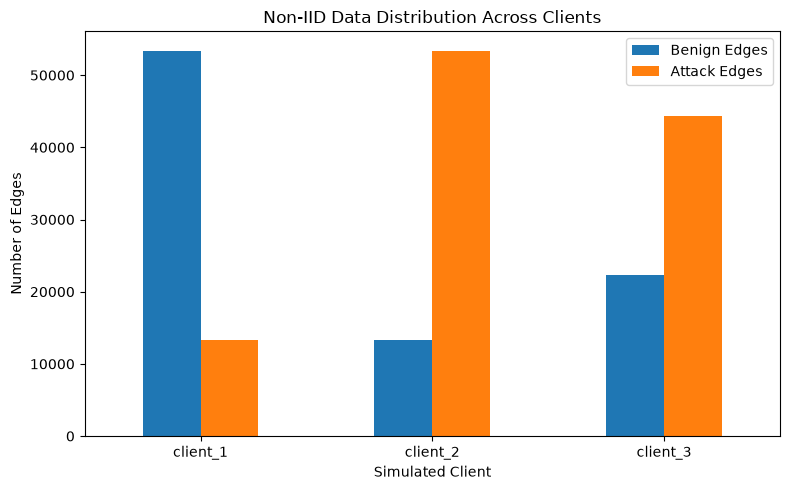

In [4]:
plot_data = distribution.set_index("Client")[
    ["Benign Edges", "Attack Edges"]
]

plot_data.plot(kind="bar", figsize=(8, 5))

plt.title("Non-IID Data Distribution Across Clients")
plt.xlabel("Simulated Client")
plt.ylabel("Number of Edges")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(OUT / "non_iid_client_distribution.png", dpi=150)
plt.show()

In [5]:
saved_clients = torch.load(
    OUT / "non_iid_clients.pt",
    map_location="cpu",
    weights_only=False
)

for name, data in saved_clients.items():
    print(
        name,
        "| features:", tuple(data["edge_features"].shape),
        "| labels:", tuple(data["edge_labels"].shape)
    )

print("\nDay 15 files:")
for path in sorted(OUT.iterdir()):
    print(path.name)

client_1 | features: (66756, 67) | labels: (66756,)
client_2 | features: (66755, 67) | labels: (66755,)
client_3 | features: (66755, 67) | labels: (66755,)

Day 15 files:
non_iid_client_distribution.csv
non_iid_client_distribution.png
non_iid_clients.pt
